In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn tensorflow


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, SimpleRNN, LSTM, GRU,
    Dense, Dropout, SpatialDropout1D
)

from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.20.0


In [3]:
df = pd.read_csv(
    "DL_T10_2C_2000_code_mixed_product_reviews.csv"
)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (2000, 7)


,review_id,product_category,review_text,sentiment,language_type,review_length,data_origin
0,TC2C00803,electronics,"Online lo order chesaka, Product smell unpleas...",negative,Romanized Telugu + English,short,synthetic_example_not_real_customer_review
1,TC2C00987,electronics,Battery/performance worst ga undi. fitness ban...,negative,Romanized Telugu + English,short,synthetic_example_not_real_customer_review
2,TC2C01235,fashion,"Recent ga cheppali ante, Nenu saree ni online ...",negative,Romanized Telugu + English,long,synthetic_example_not_real_customer_review
3,TC2C01184,electronics,"Personally, Nenu camera order chesanu but dama...",negative,Romanized Telugu + English,short,synthetic_example_not_real_customer_review
4,TC2C01537,electronics,"Na experience lo, Product expected time ki vac...",mixed,Romanized Telugu + English,short,synthetic_example_not_real_customer_review


In [4]:
print("Dataset Information:")
print(df.info())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Description:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   review_id         2000 non-null   object
 1   product_category  2000 non-null   object
 2   review_text       2000 non-null   object
 3   sentiment         2000 non-null   object
 4   language_type     2000 non-null   object
 5   review_length     2000 non-null   object
 6   data_origin       2000 non-null   object
dtypes: object(7)
memory usage: 109.5+ KB
None

Column Names:
['review_id', 'product_category', 'review_text', 'sentiment', 'language_type', 'review_length', 'data_origin']

Missing Values:
review_id           0
product_category    0
review_text         0
sentiment           0
language_type       0
review_length       0
data_origin         0
dtype: int64

Dataset Description:


,review_id,product_category,review_text,sentiment,language_type,review_length,data_origin
count,2000,2000,2000,2000,2000,2000,2000
unique,2000,3,1779,3,1,2,1
top,TC2C00303,electronics,"Nijanga cheppalante, Look super ga undi, featu...",negative,Romanized Telugu + English,short,synthetic_example_not_real_customer_review
freq,1,1089,5,667,2000,1712,2000


In [5]:
print("Available Columns:", df.columns.tolist())

TEXT_COL = None
LABEL_COL = None

text_candidates = [
    "review", "reviews", "text", "comment",
    "comments", "review_text", "content"
]

label_candidates = [
    "sentiment", "label", "polarity",
    "rating", "class", "target"
]

for col in df.columns:
    if col.lower().strip() in text_candidates:
        TEXT_COL = col
        break

for col in df.columns:
    if col.lower().strip() in label_candidates:
        LABEL_COL = col
        break

# Automatically identify a text column if necessary
if TEXT_COL is None:
    object_cols = df.select_dtypes(include="object").columns.tolist()
    if object_cols:
        TEXT_COL = max(
            object_cols,
            key=lambda c: df[c].astype(str).str.len().mean()
        )

print("Detected Text Column:", TEXT_COL)
print("Detected Label Column:", LABEL_COL)

# If automatic detection is incorrect, manually set:
# TEXT_COL = "your_review_column"
# LABEL_COL = "your_sentiment_column"

Available Columns: ['review_id', 'product_category', 'review_text', 'sentiment', 'language_type', 'review_length', 'data_origin']
Detected Text Column: review_text
Detected Label Column: sentiment


In [6]:
# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing review text
df = df.dropna(subset=[TEXT_COL])

# Remove missing labels if a label column exists
if LABEL_COL is not None:
    df = df.dropna(subset=[LABEL_COL])

# Convert review text to string
df[TEXT_COL] = df[TEXT_COL].astype(str)

# Text preprocessing function
def preprocess_text(text):

    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Keep Unicode letters, numbers and spaces
    text = re.sub(r'[^\w\s]', ' ', text, flags=re.UNICODE)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

df["cleaned_text"] = df[TEXT_COL].apply(preprocess_text)

print("Text preprocessing completed!")

display(df[[TEXT_COL, "cleaned_text"]].head())

Text preprocessing completed!


,review_text,cleaned_text
0,"Online lo order chesaka, Product smell unpleas...",online lo order chesaka product smell unpleasa...
1,Battery/performance worst ga undi. fitness ban...,battery performance worst ga undi fitness band...
2,"Recent ga cheppali ante, Nenu saree ni online ...",recent ga cheppali ante nenu saree ni online l...
3,"Personally, Nenu camera order chesanu but dama...",personally nenu camera order chesanu but damag...
4,"Na experience lo, Product expected time ki vac...",na experience lo product expected time ki vach...


In [7]:
if LABEL_COL is None:
    raise ValueError(
        "No sentiment/label/rating column detected. "
        "Please set LABEL_COL manually in Cell 5."
    )

# Convert numeric ratings into sentiment classes
if "rating" in LABEL_COL.lower():
    ratings = pd.to_numeric(df[LABEL_COL], errors="coerce")

    if ratings.notna().all():
        unique_ratings = sorted(ratings.unique())

        if len(unique_ratings) > 2:
            def rating_to_sentiment(r):
                if r <= 2:
                    return "Negative"
                elif r == 3:
                    return "Neutral"
                else:
                    return "Positive"

            df["sentiment"] = ratings.apply(rating_to_sentiment)
        else:
            df["sentiment"] = ratings.astype(str)
    else:
        df["sentiment"] = df[LABEL_COL].astype(str)
else:
    df["sentiment"] = df[LABEL_COL].astype(str).str.strip()

# Remove empty text
df = df[df["cleaned_text"].str.len() > 0]

# Encode sentiment labels
label_encoder = LabelEncoder()

df["encoded_label"] = label_encoder.fit_transform(
    df["sentiment"]
)

print("Sentiment Classes:")
print(label_encoder.classes_)

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

print("\nLabel Encoding Completed!")

Sentiment Classes:
['mixed' 'negative' 'positive']

Sentiment Distribution:
sentiment
negative    667
positive    667
mixed       666
Name: count, dtype: int64

Label Encoding Completed!


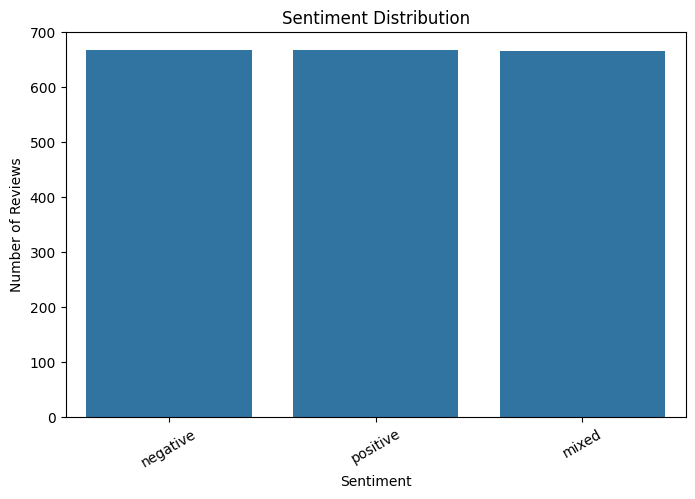

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment",
    order=df["sentiment"].value_counts().index
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=30)
plt.show()

In [9]:
MAX_WORDS = 10000
MAX_LEN = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Fit tokenizer on review text
tokenizer.fit_on_texts(df["cleaned_text"])

# Convert text into sequences
sequences = tokenizer.texts_to_sequences(
    df["cleaned_text"]
)

# Padding sequences
X = pad_sequences(
    sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

y = df["encoded_label"].values

vocab_size = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

num_classes = len(label_encoder.classes_)

print("Tokenization Completed!")
print("Vocabulary Size:", vocab_size)
print("Maximum Sequence Length:", MAX_LEN)
print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

print("\nExample Tokenized Sequence:")
print(X[0])

Tokenization Completed!
Vocabulary Size: 308
Maximum Sequence Length: 100
Input Shape: (2000, 100)
Output Shape: (2000,)

Example Tokenized Sequence:
[ 39   5  21  24   6 299 300   2   3  67 301   2   3   4  56  62   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0]


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Samples: 1600
Testing Samples: 400
Training Data Shape: (1600, 100)
Testing Data Shape: (400, 100)


In [11]:
def create_simple_rnn():

    model = Sequential([
        Embedding(
            input_dim=vocab_size,
            output_dim=64,
            input_length=MAX_LEN
        ),

        SpatialDropout1D(0.2),

        SimpleRNN(
            64,
            dropout=0.2,
            recurrent_dropout=0.0
        ),

        Dense(32, activation="relu"),

        Dropout(0.3),

        Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


simple_rnn_model = create_simple_rnn()

simple_rnn_model.summary()

C:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ spatial_dropout1d (SpatialDropout1D) │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn (SimpleRNN)               │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_rnn = simple_rnn_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("SimpleRNN Training Completed!")

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.4547 - loss: 1.0368 - val_accuracy: 0.5719 - val_loss: 0.9289
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.5805 - loss: 0.8861 - val_accuracy: 0.7125 - val_loss: 0.7333
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.6617 - loss: 0.7322 - val_accuracy: 0.6844 - val_loss: 0.6896
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7594 - loss: 0.5609 - val_accuracy: 0.6750 - val_loss: 0.6318
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7750 - loss: 0.5308 - val_accuracy: 0.8562 - val_loss: 0.3885
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.8406 - loss: 0.4487 - val_accuracy: 0.8094 - val_loss: 0.4505
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.7930 - loss: 0.5350 - val_accuracy: 0.7844 - val_loss: 0.4490
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8859 - loss: 0.3068 - val_accuracy: 0.8313 - v

In [13]:
def create_lstm():

    model = Sequential([
        Embedding(
            input_dim=vocab_size,
            output_dim=64,
            input_length=MAX_LEN
        ),

        SpatialDropout1D(0.2),

        LSTM(
            64,
            dropout=0.2
        ),

        Dense(32, activation="relu"),

        Dropout(0.3),

        Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


lstm_model = create_lstm()

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ spatial_dropout1d_1                  │ ?                           │               0 │
│ (SpatialDropout1D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [14]:
history_lstm = lstm_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM Training Completed!")

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 75ms/step - accuracy: 0.3344 - loss: 1.1006 - val_accuracy: 0.3438 - val_loss: 1.0985
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - accuracy: 0.3375 - loss: 1.0986 - val_accuracy: 0.3438 - val_loss: 1.0990
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy: 0.3227 - loss: 1.0996 - val_accuracy: 0.3094 - val_loss: 1.0997
LSTM Training Completed!


In [15]:
def create_gru():

    model = Sequential([
        Embedding(
            input_dim=vocab_size,
            output_dim=64,
            input_length=MAX_LEN
        ),

        SpatialDropout1D(0.2),

        GRU(
            64,
            dropout=0.2
        ),

        Dense(32, activation="relu"),

        Dropout(0.3),

        Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


gru_model = create_gru()

gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ spatial_dropout1d_2                  │ ?                           │               0 │
│ (SpatialDropout1D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru (GRU)                            │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [16]:
history_gru = gru_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("GRU Training Completed!")

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.3203 - loss: 1.1002 - val_accuracy: 0.3094 - val_loss: 1.0994
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.3203 - loss: 1.0993 - val_accuracy: 0.3469 - val_loss: 1.0986
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.3156 - loss: 1.0998 - val_accuracy: 0.3469 - val_loss: 1.0987
GRU Training Completed!


In [17]:
models = {
    "SimpleRNN": simple_rnn_model,
    "LSTM": lstm_model,
    "GRU": gru_model
}

results = {}
predictions = {}

for name, model in models.items():

    loss, accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    y_pred = np.argmax(
        model.predict(X_test, verbose=0),
        axis=1
    )

    predictions[name] = y_pred

    results[name] = {
        "Accuracy": accuracy,
        "Loss": loss
    }

    print("\n", "=" * 45)
    print(name, "Evaluation")
    print("=" * 45)

    print("Test Accuracy:", round(accuracy * 100, 2), "%")
    print("Test Loss:", round(loss, 4))

    print("\nClassification Report:")

    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    ))


SimpleRNN Evaluation
Test Accuracy: 88.75 %
Test Loss: 0.4475

Classification Report:
              precision    recall  f1-score   support

       mixed       0.83      1.00      0.91       133
    negative       0.90      0.84      0.87       134
    positive       0.96      0.82      0.88       133

    accuracy                           0.89       400
   macro avg       0.89      0.89      0.89       400
weighted avg       0.89      0.89      0.89       400


LSTM Evaluation
Test Accuracy: 33.5 %
Test Loss: 1.0986

Classification Report:
              precision    recall  f1-score   support

       mixed       0.00      0.00      0.00       133
    negative       0.34      1.00      0.50       134
    positive       0.00      0.00      0.00       133

    accuracy                           0.34       400
   macro avg       0.11      0.33      0.17       400
weighted avg       0.11      0.34      0.17       400


GRU Evaluation
Test Accuracy: 33.25 %
Test Loss: 1.0987

Classificati

In [18]:
results_df = pd.DataFrame(results).T

print("MODEL COMPARISON RESULTS")

display(results_df)

best_model_name = results_df["Accuracy"].idxmax()

print("\nBest Performing Model:", best_model_name)

print(
    "Best Accuracy:",
    round(results_df.loc[best_model_name, "Accuracy"] * 100, 2),
    "%"
)

MODEL COMPARISON RESULTS


,Accuracy,Loss
SimpleRNN,0.8875,0.447462
LSTM,0.3350,1.098609
GRU,0.3325,1.098735



Best Performing Model: SimpleRNN
Best Accuracy: 88.75 %


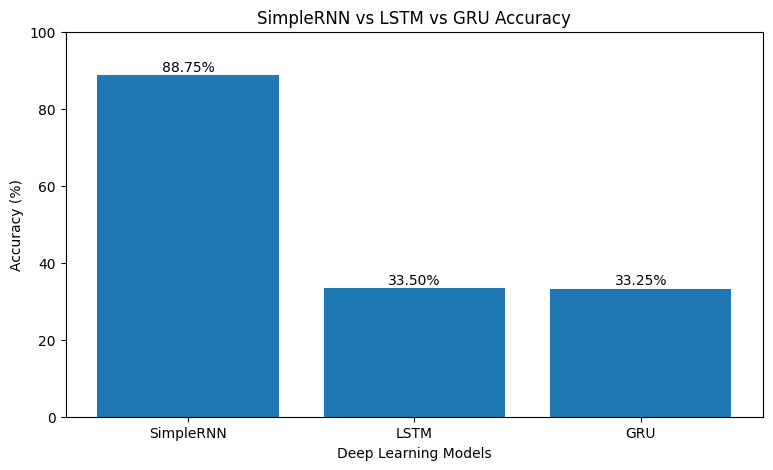

In [19]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df.index,
    results_df["Accuracy"] * 100
)

plt.title("SimpleRNN vs LSTM vs GRU Accuracy")
plt.xlabel("Deep Learning Models")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)

for i, value in enumerate(results_df["Accuracy"] * 100):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

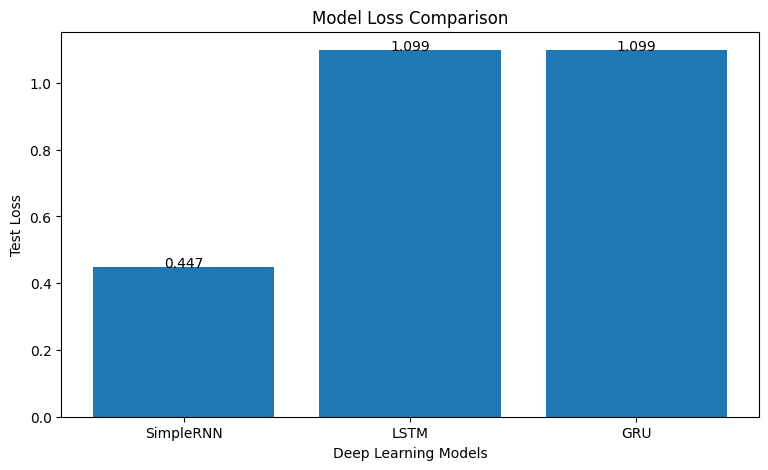

In [20]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df.index,
    results_df["Loss"]
)

plt.title("Model Loss Comparison")
plt.xlabel("Deep Learning Models")
plt.ylabel("Test Loss")

for i, value in enumerate(results_df["Loss"]):
    plt.text(i, value, f"{value:.3f}", ha="center")

plt.show()

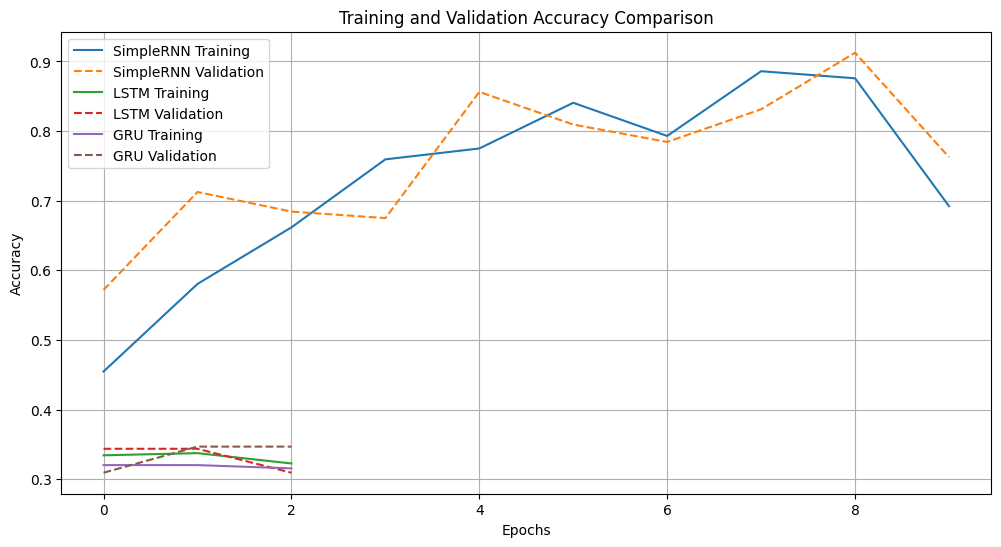

In [21]:
histories = {
    "SimpleRNN": history_rnn,
    "LSTM": history_lstm,
    "GRU": history_gru
}

plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history.history["accuracy"],
        label=name + " Training"
    )

    plt.plot(
        history.history["val_accuracy"],
        linestyle="--",
        label=name + " Validation"
    )

plt.title("Training and Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

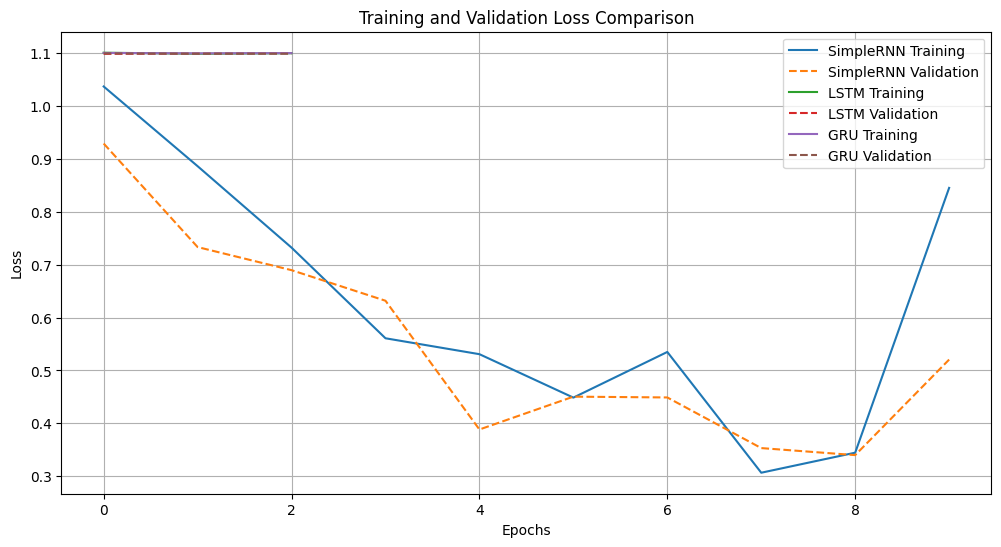

In [22]:
plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history.history["loss"],
        label=name + " Training"
    )

    plt.plot(
        history.history["val_loss"],
        linestyle="--",
        label=name + " Validation"
    )

plt.title("Training and Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

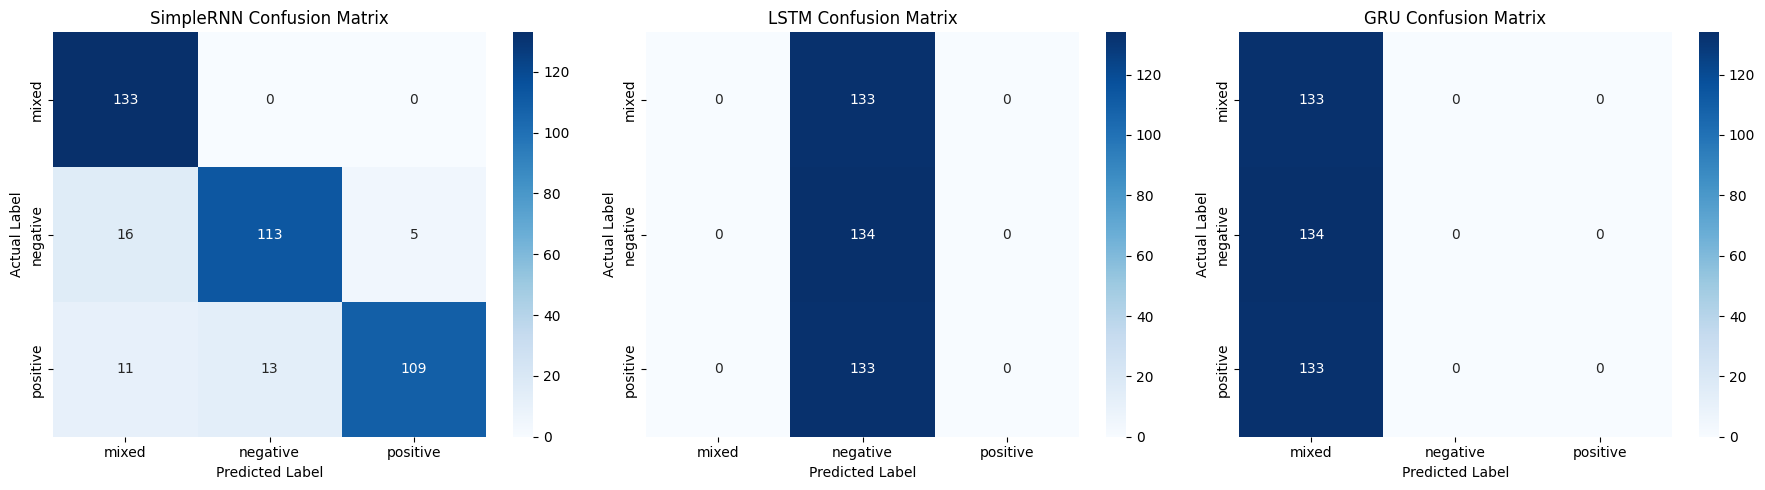

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(num_classes)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax
    )

    ax.set_title(name + " Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [25]:
final_results = pd.DataFrame({
    "Model": results_df.index,
    "Accuracy (%)": results_df["Accuracy"].values * 100,
    "Loss": results_df["Loss"].values
})

# Sort using the correct column name
final_results = final_results.sort_values(
    by="Accuracy (%)",
    ascending=False
)

final_results["Accuracy (%)"] = final_results["Accuracy (%)"].round(2)
final_results["Loss"] = final_results["Loss"].round(4)

print("FINAL MODEL PERFORMANCE")

display(final_results)

# Identify best model
best_model_name = final_results.iloc[0]["Model"]

print("\nBest Model:", best_model_name)
print("Best Accuracy:", final_results.iloc[0]["Accuracy (%)"], "%")

FINAL MODEL PERFORMANCE


,Model,Accuracy (%),Loss
0,SimpleRNN,88.75,0.4475
1,LSTM,33.50,1.0986
2,GRU,33.25,1.0987



Best Model: SimpleRNN
Best Accuracy: 88.75 %


In [26]:
best_model = models[best_model_name]

best_model.save("best_sentiment_model.keras")

print("Best Model Saved Successfully!")
print("Saved Model:", best_model_name)

Best Model Saved Successfully!
Saved Model: SimpleRNN


In [27]:
def predict_sentiment(review):

    cleaned = preprocess_text(review)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    prediction = best_model.predict(
        padded,
        verbose=0
    )

    predicted_class = np.argmax(prediction)

    sentiment = label_encoder.inverse_transform(
        [predicted_class]
    )[0]

    confidence = np.max(prediction) * 100

    print("Product Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("Confidence:", round(confidence, 2), "%")


# Example reviews
predict_sentiment("This product is very good and amazing")

predict_sentiment("Worst product, I don't like it")

Product Review: This product is very good and amazing
Predicted Sentiment: positive
Confidence: 92.09 %
Product Review: Worst product, I don't like it
Predicted Sentiment: mixed
Confidence: 98.44 %
